# Assigment Senior Data Analyst
The dataframe have the following information:

 - **city**: The city where the listing is located
 - **category**: Private Room, Shared Room, Apartment, Studio
 - **country_code**: Country code of the listing
 - **created_at**: Timestamp of listing creation
 - **price**: Monthly rent in Euros
 - **furnished**: Is the listing furnished [Yes/No]
 - **total_size**: Size in square meter of the property
 - **registration_possible**: If it’s possible to use listing’s address for registering at the city's municipality.
 - **washing_machine**: Is there a washing machine available in the
property
 - **tv**: Is there a tv available in the property
 - **balcony**: Is there a balcony available in the property
 - **garden**: Is there a garden available in the property
 - **terrace**: Is there a terrace available in the propert

## Business question: 
1. what are the 3 most important KPIs/Metrics for HousingAnywhere
and Why?
2. Suggest an approach to improve the KPIs/Metrics.
3. What are competitors doing better that HousingAnywhere is not?

## Programming Analysis and Data Visualization:
**Task 1:** Clean the dataset, provide code and explain the steps (Either SQL or any programming language).

**Task 2:** Write SQL queries and create a graphical representation for the following topics and
interpret the results:
- Price development over time
- Geographical distribution & defining cities of interest
- Any other interesting insights

# Introduction and general information 


HousingAnywhere is a renting house platform across Europe (in this example we are focusing in Italy), so basicaly we have 2 types of customers:
- **Tenants**: Composed by students, expats and young professionals.
- **Landlords and property managers**: here the company works with universities, Companies and recruitment and relocation agencies. 

The company make money with:
- **Commission fee**: when the property is rented each part have to pay 25% of the first month of rent (not over the contract value, minimum fee 150 euros). For this reason, the price is very important. Properties more expensives gives the company more benefits (properties below 600 euros have the same commission fee).
- I guess that the company receive a kind of comission from electronic payment card companies (such as mastercard) when people pay deposit, monthly rent and extras. So, is not only the sales service (at the moment of rent a property), there is a post sale service too.

The company as a platform have:
- **visitors**: this are associated with the top part of the funnel (**lead Generation - Awareness**). A person can visit the site but don't rent anything.
- **Users**: people who already register on the site as a tenant or landlord, but they don't spend money on the site yet. Users are associated with the middle part of the funnel (**lead nurture - Consideration**). For instance, a landlord can publish a place in the site but it doesn't mean that the place is going to be rented (at least in the site), if the place is not rented or if the place is rented in another site, then the landlord is not going to spend money in the company.
- **Clients**: when the contract is made, the users pay the commission fee and they became clients, this is associated with the bottom of the funnel (**sales - Conversions**). If we know how the contract last, we can know if the client keep operating with the company or not.

When we define a kpi we need to use the acronym SMARTER, what they mean is that KPIs should be:

- **Specific**: What exactly do you want to achieve?
- **Measurable**: How will you identify that you have achieved your goal?
- **Achievable**: Is your goal really attainable?
- **Relevant**:  Is it relevant to you or, in other words, does it align with where you want to be?
- **Time-Bound (or timely)**: When will you deliver your goal, and what are the key milestones?
- **Explainable**: easy to understand for your peers. 
- **Relative**: measured in percentages, or other methods which avoid “vanity metrics”.

All this measures can be split using information from Google Analytics or from our platform if the person is register by: 
- Category of customer (tenant or landlord).
- City.
- Demografic variables such as age, gender, socioeconomical level, civil status 
- Some other indicator variables such as student or not, expats or local, professionals or not.
- time variables: such us hour, day of the week, month, etc. 
- Campaign: from here there is information about Channel, Publisher, etc.

An important fact to consider is that not all the campaigns are focus on the same objective, for this reason, some campaigns can have a good registration rate but a poor conversion rate.

In my opinion the most important KPIs are:
- **Registration rate**: Measure as the percentaje of visitor who are not users who became clients. This is important because is a way of figure out if our awareness campaigns are working or not and splitting using measures it can be assess what are the marketing campaigns that we need to invest more, and where we need to invest less or stop investing.

- **Conversion rate**: Measure as the percentage of users who are looking for a house (we can figure out watching the users who visit the site) and became clients. This is important because is a way of figure out if our conversion campaign are working or not and splitting using measures it can be assess what are the marketing campaigns that we need to invest more, and where we need to invest less or stop investing.

- **Churn**: Measure as percentage of clients that are not working with us anymore, this is a measure of retention. This is important because is a way of figure out if our retention campaign are working or not and splitting using measures it can be assess what are the retention/CRM campaigns that we need to invest more, and where we need to invest less or stop investing.

In all this cases an optimization algorithm based on the information available and applying restrictions such as the amount of money that the company have for different campaigns or the maximun number of touchpoint that we want to have with a person is the best approach.

About things that the competitors are doing better. In my opinion, i think that HousingAnywhere should offer in the platform the possibility of sell and buy a property because if a landlord wants to sell a property or a tenant wants to buy one. They need to go to one of the site competitors. Also, the cost of add this functionality is pretty low (most of it is mounted already in the platform). 

Finally, looking at the opinion about the company (https://es.trustpilot.com/review/housinganywhere.com?languages=all), most of them complain because the house doesn't look like in the photos. Maybe HousingAnywhere could offer for an additional price the possibility of provide a person to go with the tenant the day where the property is deliver or some days before to check that everything is like the photos.


## 0. Import libraries and data

In [3]:
!pip install geopandas
import pandas as pd
import numpy as np
import datetime as dt
import matplotlib.pyplot as plt
pd.set_option('display.max_columns', None)
pd.set_option('max_colwidth', None)
import seaborn as sns
import geopandas as gpd
from IPython.display import display, Markdown, Latex

from shapely.geometry import Point, LineString, Polygon
from shapely import ops
from geopandas import GeoDataFrame


from google.colab import drive
drive.mount('/content/gdrive')

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
     |████████████████████████████████| 1.0 MB 13.9 MB/s 
     |████████████████████████████████| 6.3 MB 53.4 MB/s 
     |████████████████████████████████| 16.7 MB 57.2 MB/s 
Mounted at /content/gdrive


Read the data

In [4]:
# user parameters
path = r'gdrive/My Drive/Data Science Project/HousingAnywhere/' 

In [5]:
# map - shapefile
map = gpd.read_file('zip://'+path+'stanford-mn871sp9778-shapefile.zip')

# read the database assessment
df = pd.read_csv(path+'ha_data_assessement.csv',parse_dates=['created_at'],na_values='""') 

#Public data from cities from italy: https://simplemaps.com/data/it-cities
pop = pd.read_csv(path+'it.csv') 

In [6]:
print(df.shape)
df.head()

(10000, 13)


,city,category,country_code,created_at,price,furnished,total_size,registration_possible,washing_machine,tv,balcony,garden,terrace
0,Trento,Shared Room,it,2016-03-12 12:31:31,190.0,"""yes""",NaN,NaN,"""no""","""yes""","""no""","""no""","""no"""
1,Milan,Apartment,it,2019-11-14 14:48:10,3200.0,"""yes""","""50""","""yes""","""yes""","""yes""",NaN,"""no""",NaN
2,Milan,Shared Room,it,2019-10-07 10:08:21,660.0,"""yes""","""180""",NaN,"""yes""",NaN,NaN,NaN,NaN
3,Pisa,Shared Room,it,2017-07-05 11:41:57,245.0,"""yes""","""140""","""no""","""yes""","""no""",NaN,"""no""",NaN
4,Bologna,Private Room,it,2017-11-16 08:55:46,500.0,"""yes""","""18""",NaN,"""yes""","""no""",NaN,NaN,NaN


In [7]:
print(pop.shape)
pop.head()

(3373, 9)


,city,lat,lng,country,iso2,admin_name,capital,population,population_proper
0,Rome,41.8931,12.4828,Italy,IT,Lazio,primary,2872800,2872800
1,Milan,45.4669,9.1900,Italy,IT,Lombardy,admin,1366180,1366180
2,Naples,40.8333,14.2500,Italy,IT,Campania,admin,966144,966144
3,Turin,45.0667,7.7000,Italy,IT,Piedmont,admin,870952,870952
4,Palermo,38.1157,13.3613,Italy,IT,Sicilia,admin,668405,668405


## 1. Cleaning the database
When the data was read, created_at was set up as date and empty cells "" were set up  as NA values. 

In this step we made the following:
- Delete duplicates, if there is a building with the same feature upload in the same minute, we can infer that is the same that was upload 2 times and there was a problem with the browser or a web issue that send the information 2 or more times.
- replace '"', i.e. "yes" --> yes.
- set up total size as numerical field.
- created_at hour, minutes and second was discard because is not important the moment where the anounce was created, only the specific day.
- Properties without city will be deleted (595 records) because is not possible to rent a property if the tenant doesn't know where it is.
- Country code have only one value, so it was deleted.
- There is one properties with prices over 80000 (outliers), this was deleted because it look like the price of the house not the price of the rent.
- There are 49 properties with prices under 10 euros per month. This examples should be studied, because can be a price per day or can be made with the idea of avoid pay commissions. In this case, this records are going to be deleted.
- Total size in properties with total size below 5 square meters will be set up in NA.

in this step duplicate data are deleted and replace "", i.e. "yes" --> yes.

In [8]:
print(df.shape)
df.drop_duplicates(keep='last', inplace = True) 
print(df.shape) # we delete 5 duplicates

df.replace('"','', regex=True,inplace = True)
df['total_size'] =  pd.to_numeric(df.total_size, errors='coerce')

(10000, 13)
(9995, 13)


In [9]:
df.dtypes

city                             object
category                         object
country_code                     object
created_at               datetime64[ns]
price                           float64
furnished                        object
total_size                      float64
registration_possible            object
washing_machine                  object
tv                               object
balcony                          object
garden                           object
terrace                          object
dtype: object

Most of the category fields have only 2 or 3 categories (yes/no/shared). Also there are a lot of data with missings, for instance we only know for 1.388 properties if the property have balcony or not. It is suggested to encorage landlord to fill the data properly, we can suggest them an answer based on the photos uploaded. For instance, if the landlord post a photo of the balcony, the place probably have a shared or individual one.

Properties without city will be deleted because is not possible to rent a property if the tenant doesn't know where it is.

Country code have only one value, so it will be deleted.


In [10]:
df.describe(include=[object])

,city,category,country_code,furnished,registration_possible,washing_machine,tv,balcony,garden,terrace
count,9400,9396,9995,6037,4374,7754,6611,1388,5959,1233
unique,30,4,1,2,2,2,2,3,3,3
top,Milan,Private Room,it,yes,yes,yes,yes,shared,no,no
freq,2144,5558,9995,5151,3646,7357,4451,520,4455,771


In [11]:
df = df[df.city.notnull()]
df.drop(columns=['country_code'],inplace=True) #all the houses are from italy

/usr/local/lib/python3.7/dist-packages/pandas/core/frame.py:4913: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  errors=errors,


In [12]:
def get_day(x): return dt.datetime(x.year, x.month, x.day) #x.day if you want to have day too

# Create day column

df['year_created'] = df['created_at'].apply(lambda x: x.year)
df['month_created'] = df['created_at'].apply(lambda x: x.month)
df['day_created'] = df['created_at'].apply(lambda x: x.day)
df['hour_created'] = df['created_at'].apply(lambda x: x.hour)
df['minute_created'] = df['created_at'].apply(lambda x: x.minute)
df['created_at'] = df['created_at'].apply(get_day) 

118 duplicate records were deleted (in all the columns except the second created). If there is a building with the same feature upload in the same minute, we can infer that is the same that was upload 2 times and there was a problem with the browser or a web issue that send the information 2 or more times.

In [13]:
print(df.shape)
df.drop_duplicates(subset=['city', 'category', 'price', 'furnished', 'total_size', 'registration_possible', 'washing_machine', 'tv', 'balcony', 'garden',
       'terrace', 'day_created', 'month_created', 'year_created','hour_created','minute_created'], keep='last', inplace = True) 
print(df.shape)

(9400, 17)
(9282, 17)


In [14]:
df.head()

,city,category,created_at,price,furnished,total_size,registration_possible,washing_machine,tv,balcony,garden,terrace,year_created,month_created,day_created,hour_created,minute_created
0,Trento,Shared Room,2016-03-12,190.0,yes,NaN,NaN,no,yes,no,no,no,2016,3,12,12,31
1,Milan,Apartment,2019-11-14,3200.0,yes,50.0,yes,yes,yes,NaN,no,NaN,2019,11,14,14,48
2,Milan,Shared Room,2019-10-07,660.0,yes,180.0,NaN,yes,NaN,NaN,NaN,NaN,2019,10,7,10,8
3,Pisa,Shared Room,2017-07-05,245.0,yes,140.0,no,yes,no,NaN,no,NaN,2017,7,5,11,41
4,Bologna,Private Room,2017-11-16,500.0,yes,18.0,NaN,yes,no,NaN,NaN,NaN,2017,11,16,8,55


In [15]:
df.describe(datetime_is_numeric=True)

,created_at,price,total_size,year_created,month_created,day_created,hour_created,minute_created
count,9282,9282.000000,4175.000000,9282.000000,9282.000000,9282.000000,9282.000000,9282.000000
mean,2017-11-27 13:10:25.985778944,661.114446,108.499401,2017.439237,6.137363,15.864253,13.344861,29.561086
min,2016-01-01 00:00:00,0.010000,0.000000,2016.000000,1.000000,1.000000,0.000000,0.000000
25%,2016-12-14 06:00:00,285.000000,55.000000,2016.000000,4.000000,8.000000,10.000000,15.000000
50%,2017-08-25 12:00:00,400.000000,85.000000,2017.000000,6.000000,16.000000,13.000000,29.000000
75%,2018-11-29 00:00:00,650.000000,120.000000,2018.000000,9.000000,24.000000,17.000000,44.000000
max,2020-02-09 00:00:00,190205.000000,10000.000000,2020.000000,12.000000,31.000000,23.000000,59.000000
std,NaN,2321.904728,280.536044,1.161750,3.246505,8.632976,4.374741,17.053109


Total size in properties with total size below 5 square meters will be set up in NA.

In [16]:
df['total_size'] = np.where(df.total_size<5, np.nan, df.total_size)

### Distribution chart - category of rent

Approximatelly 3 over 4 properties are private or shared rooms.

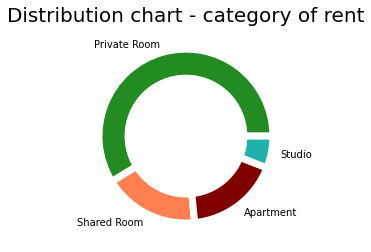

In [17]:
# create data
names=pd.value_counts(df.category).index.tolist()
color= ['forestgreen', 'coral','maroon','lightseagreen']
size=pd.value_counts(df.category).values.tolist()
 
# Create a circle for the center of the plot
my_circle=plt.Circle( (0,0), 0.7, color='white')

plt.pie(size, labels=names, wedgeprops = { 'linewidth' : 7, 'edgecolor' : 'white' }, colors=color)
p=plt.gcf()
p.gca().add_artist(my_circle)
plt.title('Distribution chart - category of rent',fontsize=20)
plt.show()

### Outliers
Delete prices above 80000, this was deleted because it look like the price of the house not the price of the rent.

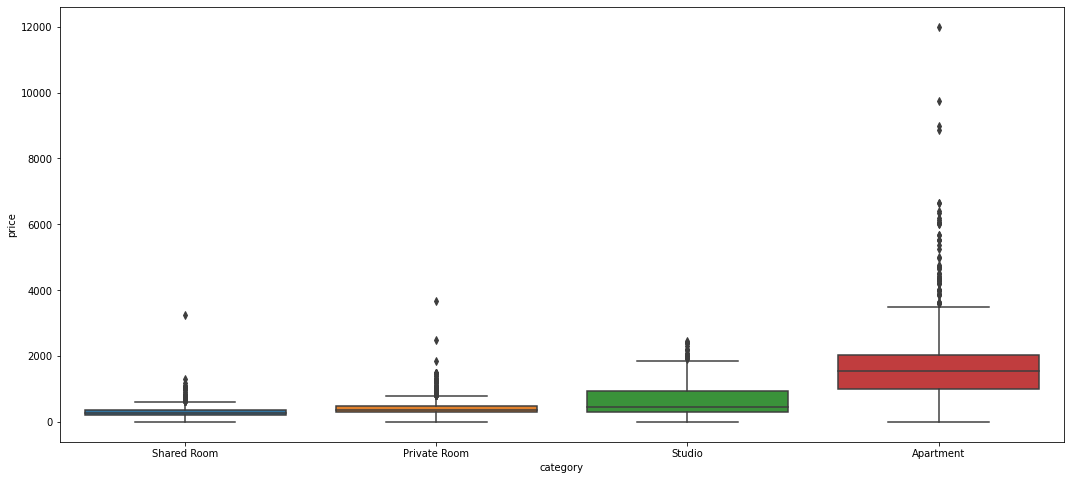

In [24]:
fig, ax = plt.subplots(1, figsize=(18, 8))
sns.boxplot(x = 'category', y = 'price', order=['Shared Room','Private Room', 'Studio',  'Apartment'], data = df)
plt.show()

From the following boxplot we can see that the price of shared and private rooms are more or less the same, a person can find a private room with the same budget that they have for a shared room, also, most of them are cheaper than 600 euros, so the company get for each rent a commission of 300 euros (the minimum). 

Then the 50% of the most expensive private rooms cost the same than the 25% of the cheapest studios. 75% of the apartments cost more than 1.000 euros. So is not so easy to get an a apartment with the budget of an studio. 


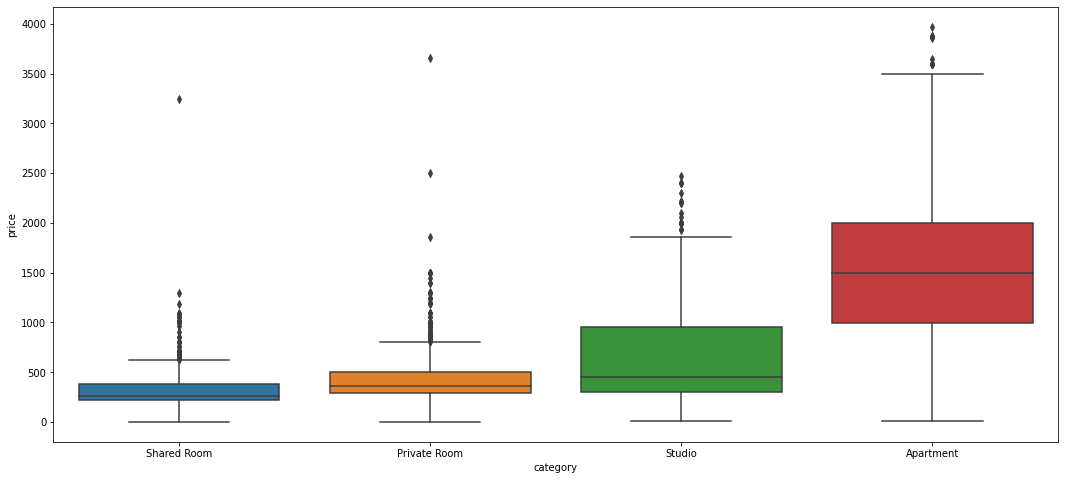

In [23]:
df=df[df.price<80000]

# Create the box plot
fig, ax = plt.subplots(1, figsize=(18, 8))
sns.boxplot(x = 'category', y = 'price', order=['Shared Room','Private Room', 'Studio',  'Apartment'] , data = df[df.price<4000])
plt.show()

### Distribution chart - price

There are 49 properties with prices under 10 euros per month. This examples should be studied, because can be a price per day or can be made with the idea of avoid pay commissions. In this case, this records are going to be deleted. 

(49, 17)


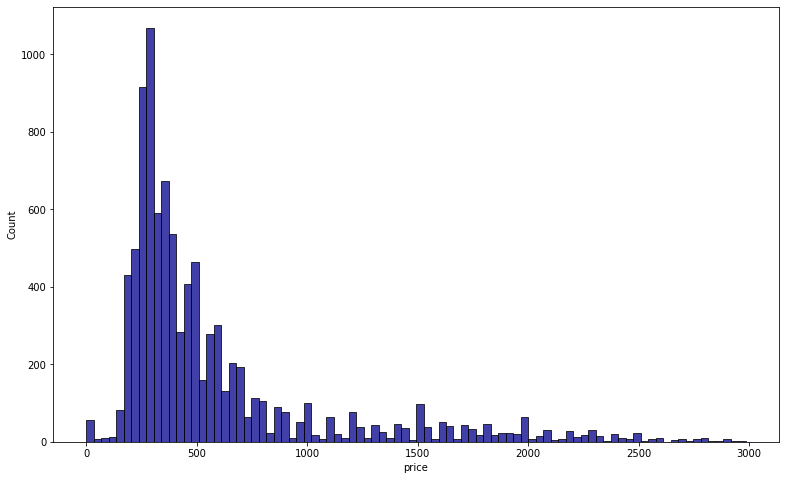

In [25]:
print(df[df.price<=10].shape)
fig = plt.figure(figsize=(13,8))
ax = sns.histplot(df[df.price<3000].price,color='darkblue');

In [102]:
df = df[df.price>10]

(49, 15)

## Price development over time

If we observed the number of properties available over the time, we see that the number of properties available decreased due to a decrease in the number of private rooms (after 2017-09). Also the number of apartments availables increase in the time, specially in the last 2 years. At the beginning, the site offer four private rooms for each apartment, but at the end the relation is one to one.

To see the price development over the time, it is going to be consider data from 2017 onwards because there is a significant number of apartments and studios after that date.


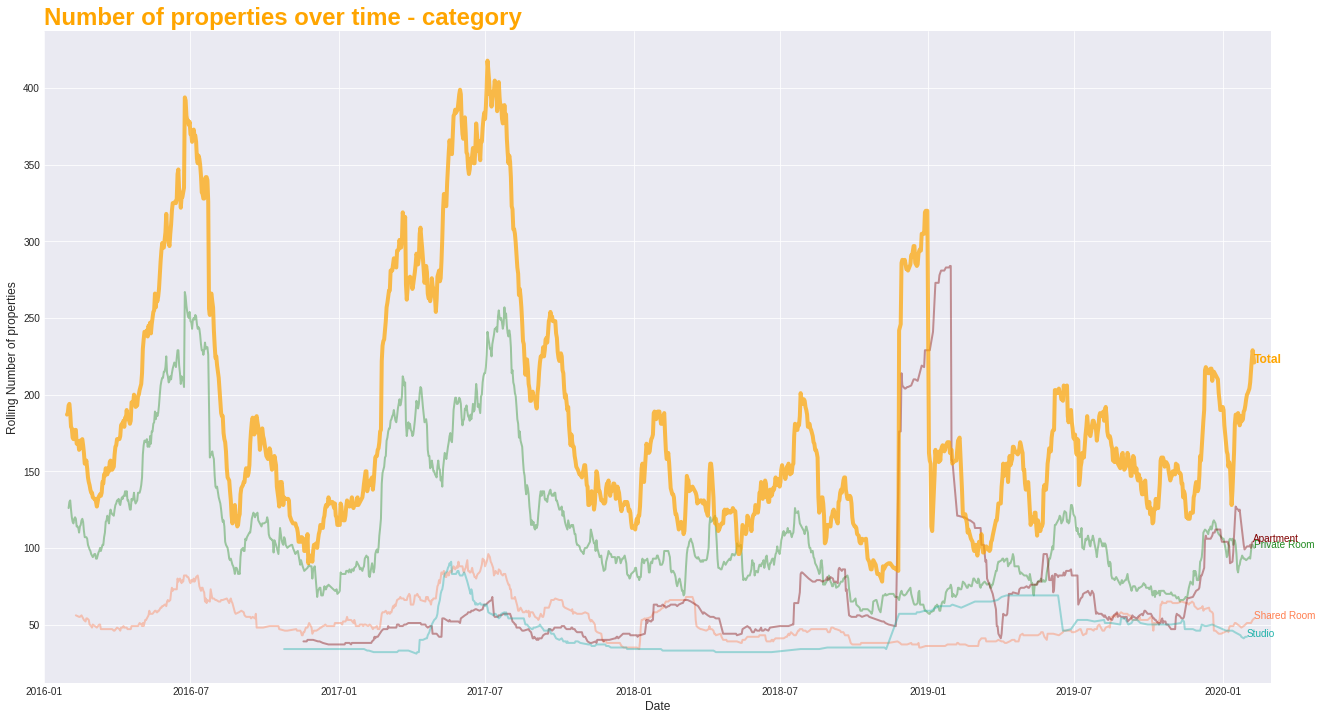

In [106]:
column = 'category'
categories=list(pd.value_counts(df[column]).index)

df_grouped=df.groupby(["created_at",column])[['price']].agg(['sum','count']).reset_index()    
df_grouped.columns = ["created_at",column,'price','properties']
df_total_per_day=df.groupby(["created_at"])[['price']].agg(['sum','count']).reset_index()  
df_total_per_day.columns = ["created_at" ,'price','properties'] 
colors= ['forestgreen', 'coral','maroon','lightseagreen']
plt.style.use('seaborn-darkgrid')
fig, ax = plt.subplots(1, figsize=(22, 12))
i=0

# multiple line plot
for clase in categories:
    data_plot=df_grouped[df_grouped[column]==clase]
    plt.plot(data_plot.created_at, 
             data_plot.properties.rolling(30).sum(), 
             marker='',color=colors[i], linewidth=2, alpha=0.4);
    i+=1


# Now re do the interesting curve, but biger with distinct color
plt.plot(df_total_per_day.created_at, df_total_per_day.properties.rolling(30).sum(), marker='', color='orange', linewidth=4, alpha=0.7)


i=0
# Let's annotate the plot
for clase in categories:
    data_plot=df_grouped[df_grouped[column]==clase]
    value=( data_plot.properties.rolling(30).sum().iloc[-1])
    plt.text(max(data_plot.created_at), value, clase, horizontalalignment='left', size='medium', color=colors[i])
    i+=1


# And add a special annotation for the group we are interested in
plt.text(max(df_total_per_day.created_at), df_total_per_day.properties.rolling(30).sum().iloc[-1]
         , 'Total', horizontalalignment='left', size='large', weight='bold' ,color='orange')

plt.xlim(pd.to_datetime('2016-01-01 00:00:00'),pd.to_datetime('2020-03-01 00:00:00'));
 
# Add titles
plt.title("Number of properties over time - "+ column, loc='left',   fontsize=24, fontweight='bold', color='orange')
plt.xlabel("Date",   fontsize=12);
plt.ylabel("Rolling Number of properties",   fontsize=12); 

Between jan 2017 and sep 2017 the avg price keep more or less constant. But after that it started to increase (from 400 to 1000 euros) due to a decrease in the number of private rooms available and also because an increase in the price of the apartments.

Despite of the seasonal deviations influenciated by the offer and the demand, the mean price of the apartments increase from 1.000 to 1.700 euros, studios from 400 to 1100 euros, private rooms from 350 to 600 euros and shared rooms from 250 to 450. So, with the same price that a person rent an apartment in 2017, now can access only to a studio, a person rent a studio in 2017, now can access only to a private room, a person rent a private room in 2017, now can access only to a shared room,

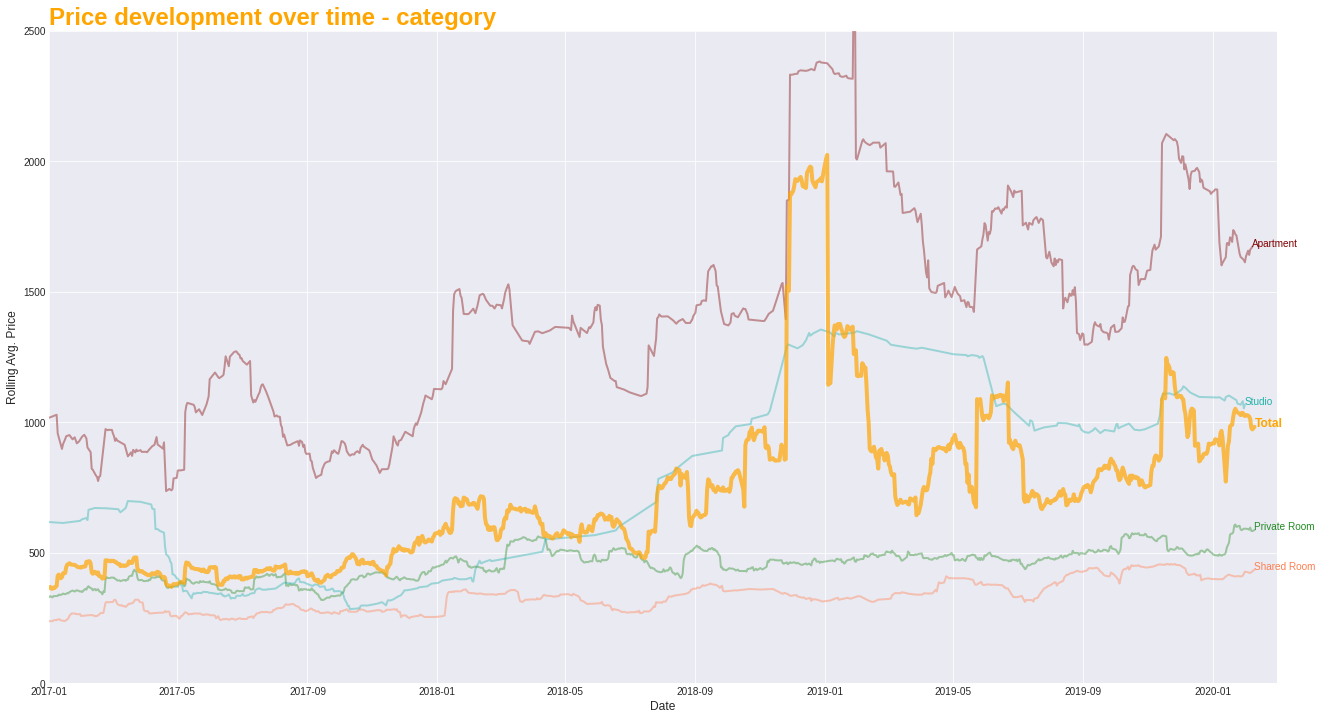

In [53]:
column = 'category'
categories=list(pd.value_counts(df[column]).index)

df_grouped=df.groupby(["created_at",column])[['price']].agg(['sum','count']).reset_index()    
df_grouped.columns = ["created_at",column,'price','properties']
df_total_per_day=df.groupby(["created_at"])[['price']].agg(['sum','count']).reset_index()  
df_total_per_day.columns = ["created_at" ,'price','properties']

colors= ['forestgreen', 'coral','maroon','lightseagreen']
plt.style.use('seaborn-darkgrid')
fig, ax = plt.subplots(1, figsize=(22, 12))
i=0

# multiple line plot
for clase in categories:
    data_plot=df_grouped[df_grouped[column]==clase]
    plt.plot(data_plot.created_at, 
             data_plot.price.rolling(30).sum()/data_plot.properties.rolling(30).sum(), 
             marker='',color=colors[i], linewidth=2, alpha=0.4);
    i+=1


# Now re do the interesting curve, but biger with distinct color
plt.plot(df_total_per_day.created_at, df_total_per_day.price.rolling(30).sum()/df_total_per_day.properties.rolling(30).sum(), marker='', color='orange', linewidth=4, alpha=0.7)


i=0
# Let's annotate the plot
for clase in categories:
    data_plot=df_grouped[df_grouped[column]==clase]
    value=(data_plot.price.rolling(30).sum().iloc[-1]/data_plot.properties.rolling(30).sum().iloc[-1])
    plt.text(max(data_plot.created_at), value, clase, horizontalalignment='left', size='medium', color=colors[i])
    i+=1


# And add a special annotation for the group we are interested in
plt.text(max(df_total_per_day.created_at), df_total_per_day.price.rolling(30).sum().iloc[-1]/df_total_per_day.properties.rolling(30).sum().iloc[-1]
         , 'Total', horizontalalignment='left', size='large', weight='bold' ,color='orange')

plt.xlim(pd.to_datetime('2017-01-01 00:00:00'),pd.to_datetime('2020-03-01 00:00:00'));
plt.ylim(0,2500)
# Add titles
plt.title("Price development over time - "+ column, loc='left',   fontsize=24, fontweight='bold', color='orange')
plt.xlabel("Date",   fontsize=12);
plt.ylabel("Rolling Avg. Price",   fontsize=12); 

Analysing the 4 cities with more properties:
- price in Pisa remains constant over the time.
- In 2019 the price in Bolonia increased from 400-450 to 700-750.
- In Milan and Florence

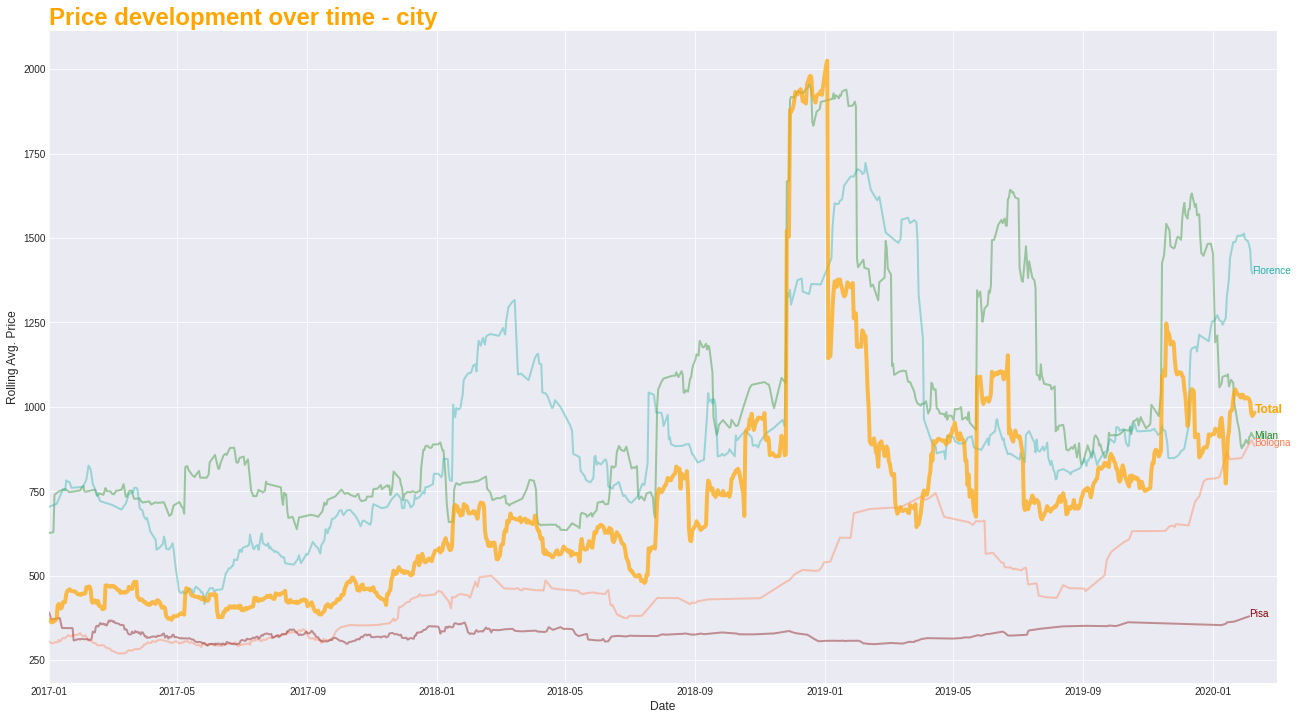

In [52]:
column = 'city'
categories=list(pd.value_counts(df[column]).index)[:4]

df_grouped=df.groupby(["created_at",column])[['price']].agg(['sum','count']).reset_index()   
df_grouped.columns = ["created_at",column,'price','properties']
df_total_per_day=df.groupby(["created_at"])[['price']].agg(['sum','count']).reset_index() 
df_total_per_day.columns = ["created_at" ,'price','properties']
##promedio_precuar=geohashes_sp[geohashes_sp.index<=pd.to_datetime('2020-03-24 00:00:00')].geo_hash_7_avg.mean()
colors= ['forestgreen', 'coral','maroon','lightseagreen']
plt.style.use('seaborn-darkgrid')
fig, ax = plt.subplots(1, figsize=(22, 12))
i=0 

# multiple line plot
for clase in categories:
    data_plot=df_grouped[df_grouped[column]==clase]
    plt.plot(data_plot.created_at, 
             data_plot.price.rolling(30).sum()/data_plot.properties.rolling(30).sum(), 
             marker='', color=colors[i], linewidth=2, alpha=0.4);
    i+=1

# Now re do the interesting curve, but biger with distinct color
plt.plot(df_total_per_day.created_at, df_total_per_day.price.rolling(30).sum()/df_total_per_day.properties.rolling(30).sum(), marker='', color='orange', linewidth=4, alpha=0.7)

i=0 
# Let's annotate the plot
for clase in categories:
    data_plot=df_grouped[df_grouped[column]==clase]
    value=(data_plot.price.rolling(30).sum().iloc[-1]/data_plot.properties.rolling(30).sum().iloc[-1])
    plt.text(max(data_plot.created_at), value, clase, horizontalalignment='left', size='medium', color=colors[i])
    i+=1

# And add a special annotation for the group we are interested in
plt.text(max(df_total_per_day.created_at), df_total_per_day.price.rolling(30).sum().iloc[-1]/df_total_per_day.properties.rolling(30).sum().iloc[-1]
         , 'Total', horizontalalignment='left', size='large', weight='bold' ,color='orange')

plt.xlim(pd.to_datetime('2017-01-01 00:00:00'),pd.to_datetime('2020-03-01 00:00:00'));

# Add titles
plt.title("Price development over time - "+ column, loc='left',   fontsize=24, fontweight='bold', color='orange')
plt.xlabel("Date",   fontsize=12);
plt.ylabel("Rolling Avg. Price",   fontsize=12); 

## Geographical distribution & defining cities of interest

In [113]:
df_city=df.groupby(["city"])[['price']].agg(['mean','count']).reset_index()   
df_city.columns = ["city",'price','properties']
df_city = pd.merge(df_city, pop,  how='left', left_on =['city'], right_on = ['city'])
df_city.dropna(subset=['admin_name'],inplace = True) # drop 3 properties from regio calabria

In [114]:
df_city['penetration_per_100thousand'] = 100000*df_city['properties']/df_city['population']
df_city['geometry'] = [Point(xy) for xy in zip(df_city.lng, df_city.lat)]

#create the geodataframe (useful to create the charts)
crs = {'init': 'epsg:4326'}
gdf_points = GeoDataFrame(df_city, geometry=df_city.geometry, crs=crs)

/usr/local/lib/python3.7/dist-packages/pandas/core/dtypes/cast.py:118: ShapelyDeprecationWarning:

The array interface is deprecated and will no longer work in Shapely 2.0. Convert the '.coords' to a numpy array instead.

/usr/local/lib/python3.7/dist-packages/pyproj/crs/crs.py:131: FutureWarning:

'+init=<authority>:<code>' syntax is deprecated. '<authority>:<code>' is the preferred initialization method. When making the change, be mindful of axis order changes: https://pyproj4.github.io/pyproj/stable/gotchas.html#axis-order-changes-in-proj-6



In [126]:
#df_city['penetration_per_thousand_plot']=df_city['penetration_per_thousand']*1000
df_city.head()

,city,price,properties,lat,lng,country,iso2,admin_name,capital,population,population_proper,penetration_per_100thousand,geometry,penetration_per_100thousand_plot
0,Ancona,225.194125,80,43.6167,13.5167,Italy,IT,Marche,admin,100924.0,100924.0,79.267568,POINT (13.51670 43.61670),79.267568
1,Bari,362.045455,44,41.1253,16.8667,Italy,IT,Puglia,admin,323370.0,323370.0,13.606704,POINT (16.86670 41.12530),50.000000
2,Bergamo,382.000000,10,45.6950,9.6700,Italy,IT,Lombardy,minor,120923.0,120923.0,8.269725,POINT (9.67000 45.69500),50.000000
3,Bologna,330.685408,1873,44.4939,11.3428,Italy,IT,Emilia-Romagna,admin,389261.0,389261.0,481.168162,POINT (11.34280 44.49390),481.168162
4,Bolzano,507.500000,10,46.5000,11.3500,Italy,IT,Trentino-Alto Adige,minor,107317.0,107317.0,9.318188,POINT (11.35000 46.50000),50.000000


In [117]:
##this field is created only for the plot purpouse
#df_city['penetration_per_thousand_plot']=df_city['penetration_per_thousand']*1000 
df_city['penetration_per_100thousand_plot']=np.where(df_city['penetration_per_100thousand']>1000, 1000,df_city['penetration_per_100thousand']) 
df_city['penetration_per_100thousand_plot']=np.where(df_city['penetration_per_100thousand_plot']<50, 50,df_city['penetration_per_100thousand_plot']) 

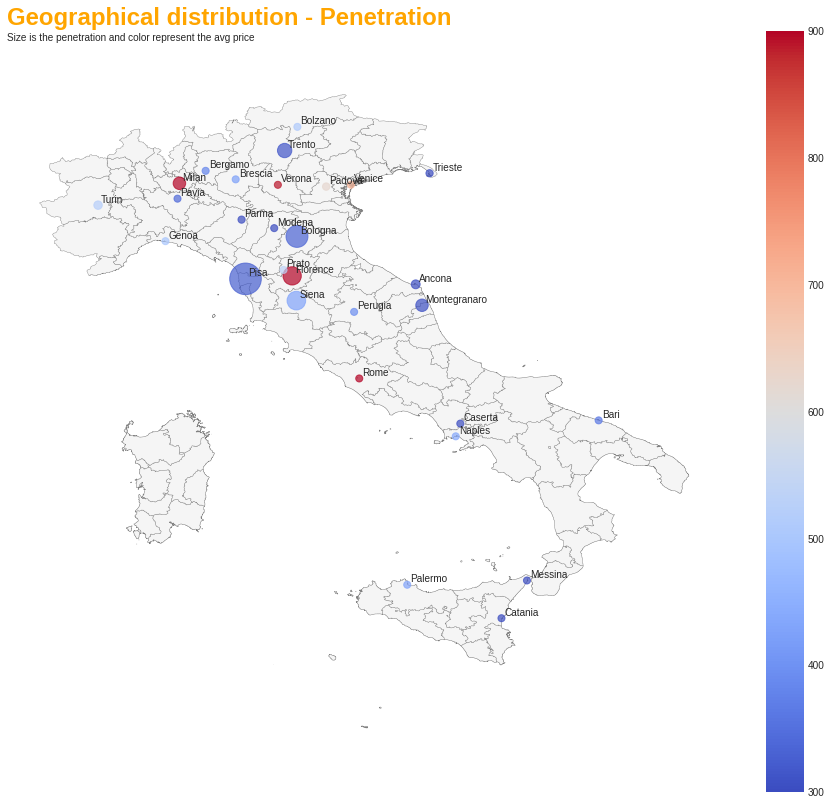

In [121]:
plt.style.use('seaborn-darkgrid')
fig, ax = plt.subplots(figsize=(16,14))
map.plot(ax=ax, color='whitesmoke', edgecolor='grey', linewidth=0.4)
gdf_points.plot('price', ax=ax, cmap='coolwarm',alpha=0.7, figsize=20,vmin=300,vmax=900,
                 markersize='penetration_per_100thousand_plot', legend=True ) 
ax.axis('off')
plt.axis('equal')

cities = gdf_points
for x, y, label in zip(cities.geometry.x, cities.geometry.y, cities.city):
    ax.annotate(label, xy=(x, y), xytext=(3, 3), textcoords="offset points")

plt.title("Geographical distribution - Penetration", loc='left', fontsize=24, fontweight='bold', color='orange')
fig.text(.34, .87, 'Size is the penetration and color represent the avg price', ha='right'); 
plt.show()

## Geographical distribution & defining cities of interest - Apartments

In [142]:
df_city=df[df.category=='Apartment'].groupby(["city"])[['price']].agg(['mean','count']).reset_index()   
df_city.columns = ["city",'price','properties']
df_city = pd.merge(df_city, pop,  how='left', left_on =['city'], right_on = ['city'])
df_city.dropna(subset=['admin_name'],inplace = True) # drop 3 properties from regio calabria

df_city['penetration_per_100thousand'] = 100000*df_city['properties']/df_city['population']
df_city['geometry'] = [Point(xy) for xy in zip(df_city.lng, df_city.lat)]

#create the geodataframe (useful to create the charts)
crs = {'init': 'epsg:4326'}
gdf_points = GeoDataFrame(df_city, geometry=df_city.geometry, crs=crs)

##this field is created only for the plot purpouse
df_city['penetration_per_100thousand_plot']=df_city['penetration_per_100thousand']*10 
df_city['penetration_per_100thousand_plot']=np.where(df_city['penetration_per_100thousand_plot']>1000, 1000,df_city['penetration_per_100thousand_plot']) 
df_city['penetration_per_100thousand_plot']=np.where(df_city['penetration_per_100thousand_plot']<50, 50,df_city['penetration_per_100thousand_plot']) 

/usr/local/lib/python3.7/dist-packages/pandas/core/dtypes/cast.py:118: ShapelyDeprecationWarning:

The array interface is deprecated and will no longer work in Shapely 2.0. Convert the '.coords' to a numpy array instead.

/usr/local/lib/python3.7/dist-packages/pyproj/crs/crs.py:131: FutureWarning:

'+init=<authority>:<code>' syntax is deprecated. '<authority>:<code>' is the preferred initialization method. When making the change, be mindful of axis order changes: https://pyproj4.github.io/pyproj/stable/gotchas.html#axis-order-changes-in-proj-6



In [143]:
df_city

,city,price,properties,lat,lng,country,iso2,admin_name,capital,population,population_proper,penetration_per_100thousand,geometry,penetration_per_100thousand_plot
0,Ancona,272.500000,4,43.6167,13.5167,Italy,IT,Marche,admin,100924.0,100924.0,3.963378,POINT (13.51670 43.61670),50.000000
1,Bari,300.000000,1,41.1253,16.8667,Italy,IT,Puglia,admin,323370.0,323370.0,0.309243,POINT (16.86670 41.12530),50.000000
2,Bologna,1055.133929,56,44.4939,11.3428,Italy,IT,Emilia-Romagna,admin,389261.0,389261.0,14.386234,POINT (11.34280 44.49390),143.862344
3,Brescia,483.333333,3,45.5389,10.2203,Italy,IT,Lombardy,minor,196745.0,196745.0,1.524816,POINT (10.22030 45.53890),50.000000
4,Caserta,550.000000,1,41.0667,14.3333,Italy,IT,Campania,minor,75561.0,75561.0,1.323434,POINT (14.33330 41.06670),50.000000
5,Catania,391.666667,9,37.5027,15.0873,Italy,IT,Sicilia,minor,311584.0,311584.0,2.888467,POINT (15.08730 37.50270),50.000000
6,Florence,1665.860830,470,43.7714,11.2542,Italy,IT,Tuscany,admin,380948.0,380948.0,123.376419,POINT (11.25420 43.77140),1000.000000
7,Genoa,890.000000,3,44.4072,8.9340,Italy,IT,Liguria,admin,580097.0,580097.0,0.517155,POINT (8.93400 44.40720),50.000000
8,Milan,1988.340647,572,45.4669,9.1900,Italy,IT,Lombardy,admin,1366180.0,1366180.0,41.868568,POINT (9.19000 45.46690),418.685678
9,Naples,966.000000,10,40.8333,14.2500,Italy,IT,Campania,admin,966144.0,966144.0,1.035042,POINT (14.25000 40.83330),50.000000


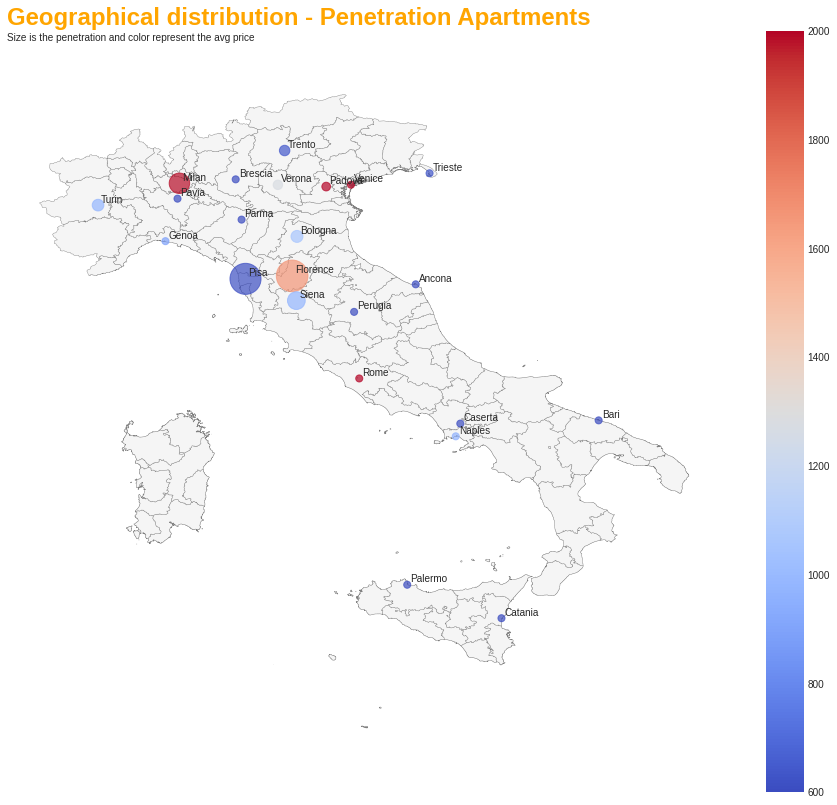

In [145]:

plt.style.use('seaborn-darkgrid')
fig, ax = plt.subplots(figsize=(16,14))
map.plot(ax=ax, color='whitesmoke', edgecolor='grey', linewidth=0.4)
gdf_points.plot('price', ax=ax, cmap='coolwarm',alpha=0.7, figsize=20,vmin=600,vmax=2000,
                 markersize='penetration_per_100thousand_plot', legend=True ) 
ax.axis('off')
plt.axis('equal')

cities = gdf_points
for x, y, label in zip(cities.geometry.x, cities.geometry.y, cities.city):
    ax.annotate(label, xy=(x, y), xytext=(3, 3), textcoords="offset points")

plt.title("Geographical distribution - Penetration Apartments", loc='left', fontsize=24, fontweight='bold', color='orange')
fig.text(.34, .87, 'Size is the penetration and color represent the avg price', ha='right'); 
plt.show()

## Geographical distribution & defining cities of interest - Rooms

In [149]:
df_city=df[(df.category=='Private Room') | (df.category=='Shared Room')].groupby(["city"])[['price']].agg(['mean','count']).reset_index()   
df_city.columns = ["city",'price','properties']
df_city = pd.merge(df_city, pop,  how='left', left_on =['city'], right_on = ['city'])
df_city.dropna(subset=['admin_name'],inplace = True) # drop 3 properties from regio calabria

df_city['penetration_per_100thousand'] = 100000*df_city['properties']/df_city['population']
df_city['geometry'] = [Point(xy) for xy in zip(df_city.lng, df_city.lat)]

#create the geodataframe (useful to create the charts)
crs = {'init': 'epsg:4326'}
gdf_points = GeoDataFrame(df_city, geometry=df_city.geometry, crs=crs)

##this field is created only for the plot purpouse
df_city['penetration_per_100thousand_plot']=df_city['penetration_per_100thousand'] 
df_city['penetration_per_100thousand_plot']=np.where(df_city['penetration_per_100thousand_plot']>500, 500,df_city['penetration_per_100thousand_plot']) 
df_city['penetration_per_100thousand_plot']=np.where(df_city['penetration_per_100thousand_plot']<50, 50,df_city['penetration_per_100thousand_plot']) 

/usr/local/lib/python3.7/dist-packages/pandas/core/dtypes/cast.py:118: ShapelyDeprecationWarning:

The array interface is deprecated and will no longer work in Shapely 2.0. Convert the '.coords' to a numpy array instead.

/usr/local/lib/python3.7/dist-packages/pyproj/crs/crs.py:131: FutureWarning:

'+init=<authority>:<code>' syntax is deprecated. '<authority>:<code>' is the preferred initialization method. When making the change, be mindful of axis order changes: https://pyproj4.github.io/pyproj/stable/gotchas.html#axis-order-changes-in-proj-6



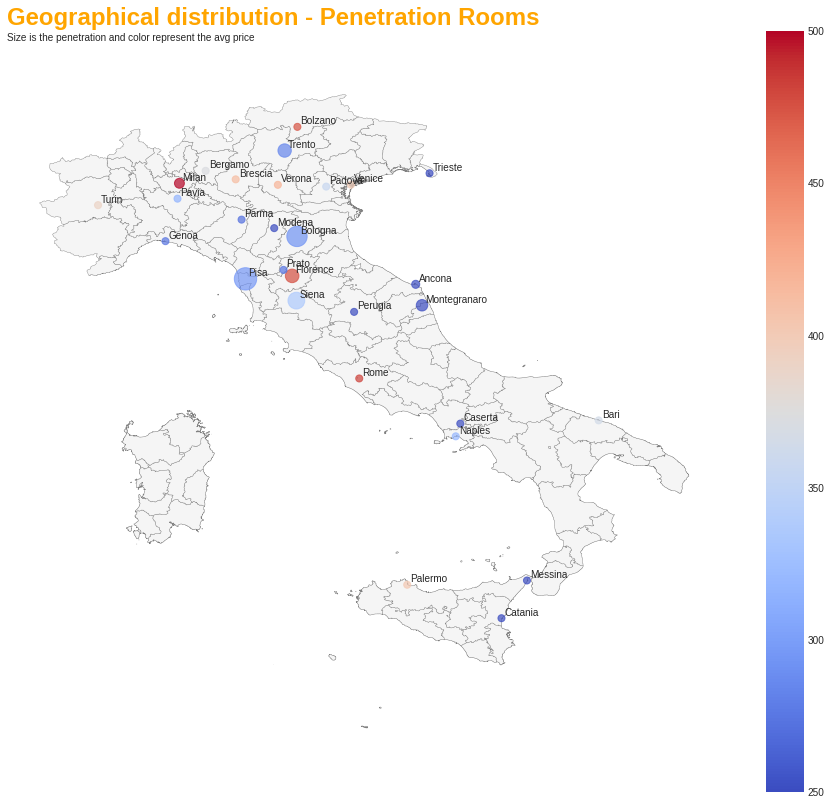

In [151]:
plt.style.use('seaborn-darkgrid')
fig, ax = plt.subplots(figsize=(16,14))
map.plot(ax=ax, color='whitesmoke', edgecolor='grey', linewidth=0.4)
gdf_points.plot('price', ax=ax, cmap='coolwarm',alpha=0.7, figsize=20,vmin=250,vmax=500,
                 markersize='penetration_per_100thousand_plot', legend=True ) 
ax.axis('off')
plt.axis('equal')

cities = gdf_points
for x, y, label in zip(cities.geometry.x, cities.geometry.y, cities.city):
    ax.annotate(label, xy=(x, y), xytext=(3, 3), textcoords="offset points")

plt.title("Geographical distribution - Penetration Rooms", loc='left', fontsize=24, fontweight='bold', color='orange')
fig.text(.34, .87, 'Size is the penetration and color represent the avg price', ha='right'); 
plt.show()

In [148]:
df_city

,city,price,properties,lat,lng,country,iso2,admin_name,capital,population,population_proper,penetration_per_100thousand,geometry,penetration_per_100thousand_plot
0,Ancona,211.636364,66,43.6167,13.5167,Italy,IT,Marche,admin,100924.0,100924.0,65.395743,POINT (13.51670 43.61670),653.957433
1,Bari,365.000000,42,41.1253,16.8667,Italy,IT,Puglia,admin,323370.0,323370.0,12.988218,POINT (16.86670 41.12530),129.882178
2,Bergamo,372.857143,7,45.6950,9.6700,Italy,IT,Lombardy,minor,120923.0,120923.0,5.788808,POINT (9.67000 45.69500),57.888078
3,Bologna,292.605762,1614,44.4939,11.3428,Italy,IT,Emilia-Romagna,admin,389261.0,389261.0,414.631828,POINT (11.34280 44.49390),1000.000000
4,Bolzano,474.166667,6,46.5000,11.3500,Italy,IT,Trentino-Alto Adige,minor,107317.0,107317.0,5.590913,POINT (11.35000 46.50000),55.909129
5,Brescia,412.890625,64,45.5389,10.2203,Italy,IT,Lombardy,minor,196745.0,196745.0,32.529416,POINT (10.22030 45.53890),325.294162
6,Caserta,216.250000,8,41.0667,14.3333,Italy,IT,Campania,minor,75561.0,75561.0,10.587472,POINT (14.33330 41.06670),105.874724
7,Catania,245.102041,49,37.5027,15.0873,Italy,IT,Sicilia,minor,311584.0,311584.0,15.726096,POINT (15.08730 37.50270),157.260963
8,Florence,477.440895,704,43.7714,11.2542,Italy,IT,Tuscany,admin,380948.0,380948.0,184.802125,POINT (11.25420 43.77140),1000.000000
9,Genoa,273.750000,8,44.4072,8.9340,Italy,IT,Liguria,admin,580097.0,580097.0,1.379080,POINT (8.93400 44.40720),50.000000
